In [1]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer

import torch

from pathlib import Path
import sys

import matplotlib.pyplot as plt

In [2]:
SRC = Path.cwd().parents[1]          # training/ -> restore_pipeline/ -> src/
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

In [3]:
from restore_pipeline.dataprocessing.dataloading import get_damaged_splits_dataloaders, get_splits_dataloaders, DataConfig

from restore_pipeline.representation.train import TrainConfig, fit, damaged_reconstruction_loss
from restore_pipeline.representation.models import ConvAutoencoder, ConvOnlyAutoencoder, encode_loader
from restore_pipeline.representation.plotting import plot_reconstructions

from restore_pipeline.clustering.plotting import umap_project, plot_clusters_2d
from restore_pipeline.clustering.utils import kmeans_sweep
from restore_pipeline.clustering.plotting import plot_kmeans_sweep

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [5]:
data_cfg = DataConfig(
    processed_path=Path("../data/wikiart_train_processed"),
    cache_dir="../data",
)
train_dmg, val_dmg, test_dmg = get_damaged_splits_dataloaders(data_cfg, mix=True)
train_clean, val_clean, test_clean = get_splits_dataloaders(data_cfg)

# ConvOnlyAutoencoder

Epochs:   0%|          | 0/7 [00:00<?, ?it/s]

Training:   0%|          | 0/2573 [00:00<?, ?it/s]

Validation:   0%|          | 0/322 [00:00<?, ?it/s]

Training:   0%|          | 0/2573 [00:00<?, ?it/s]

Validation:   0%|          | 0/322 [00:00<?, ?it/s]

Training:   0%|          | 0/2573 [00:00<?, ?it/s]

... (5 outputs left out)

Training:   0%|          | 0/2573 [00:00<?, ?it/s]

Validation:   0%|          | 0/322 [00:00<?, ?it/s]

Training:   0%|          | 0/2573 [00:00<?, ?it/s]

Validation:   0%|          | 0/322 [00:00<?, ?it/s]

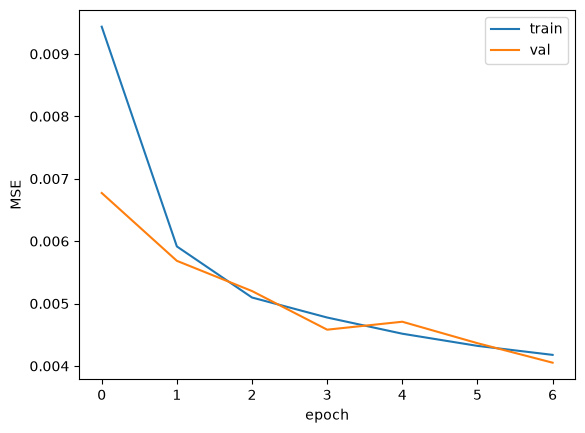

In [6]:
model = ConvOnlyAutoencoder() 
model.to(device)
train_cfg = TrainConfig(epochs=7)
history = fit(model, train_dmg, val_dmg, train_cfg, loss_fn = damaged_reconstruction_loss)

plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

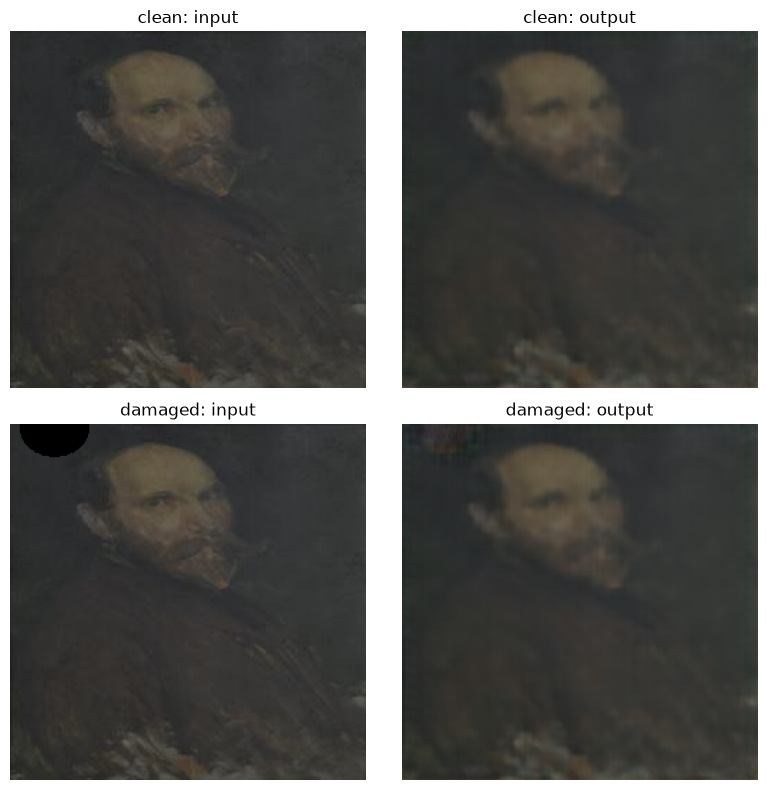

In [7]:
n_val = len(val_clean.dataset)
i = 34
clean = val_clean.dataset[i]["image"]
damaged = val_dmg.dataset[i + n_val]["image"]     # mix=True: damaged copies come after the clean ones

plot_reconstructions(model, [clean, damaged], device, titles=["clean", "damaged"])

In [8]:
embed_dmg = encode_loader(model, train_dmg, device)
embed_clean = encode_loader(model, train_clean, device)

K-means sweep:   0%|          | 0/10 [00:00<?, ?it/s]

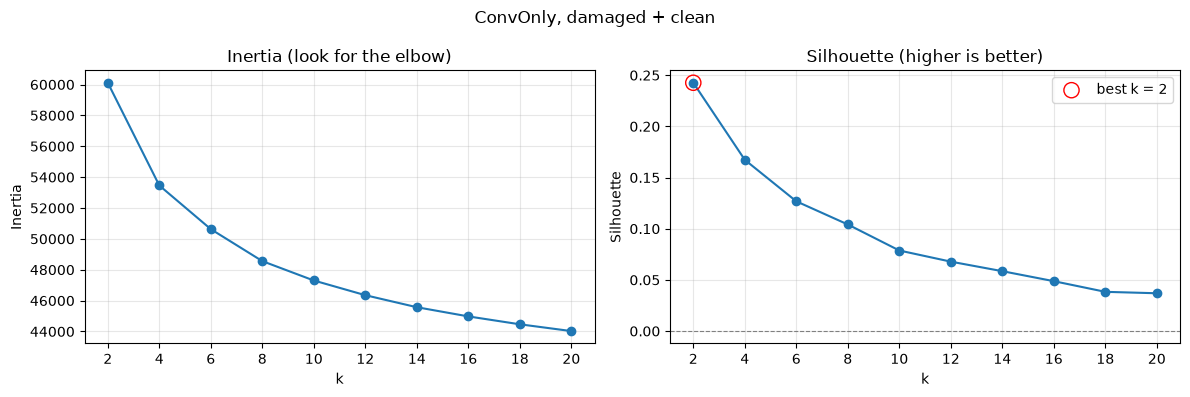

In [19]:
pipe = make_pipeline(
    PCA(n_components=256, whiten=False, random_state=42),
    Normalizer(norm="l2"),
    # KMeans(n_clusters=8, n_init=10, random_state=42),
)
features_clean = pipe.fit_transform(embed_clean)
sweep = kmeans_sweep(features_clean, range(2, 21, 2))
plot_kmeans_sweep(sweep, title="ConvOnly, damaged + clean")
plt.show()

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


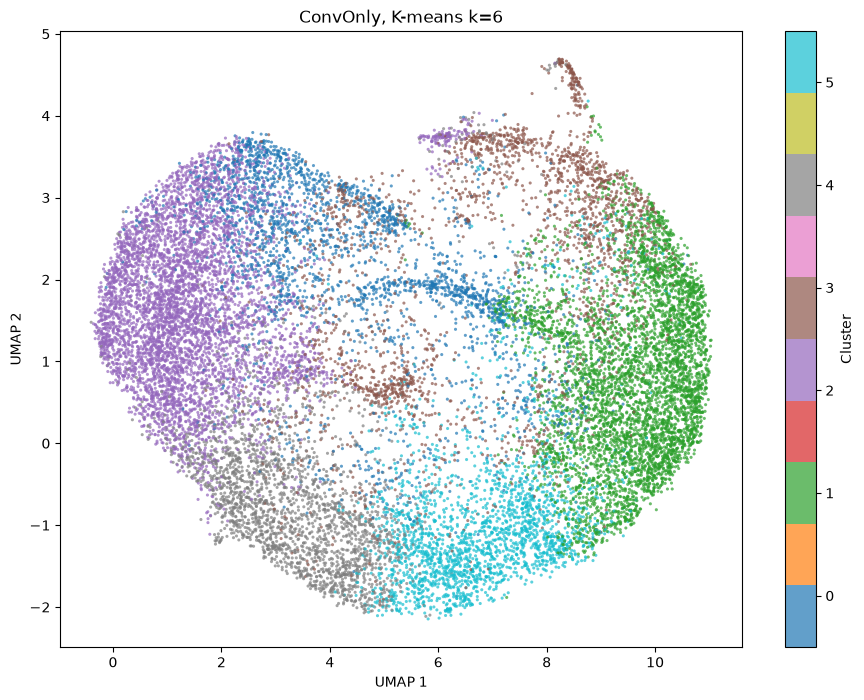

In [25]:
K = 6
labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(features_clean)

embedding_2d, idx = umap_project(features_clean)

plot_clusters_2d(embedding_2d, labels[idx], title=f"ConvOnly, K-means k={K}")
plt.show()

In [26]:
from restore_pipeline.dataprocessing.dataloading import get_splits, get_splits_dataloaders

# Same split as training, but no shuffling, so row i is the same painting everywhere.
encode_cfg = DataConfig(
    processed_path=Path("../data/wikiart_train_processed"),
    cache_dir="../data",
    shuffle_train=False,
)

# 1. Embeddings, in dataset order
train_ordered, _, _ = get_splits_dataloaders(encode_cfg)
embed = encode_loader(model, train_ordered, device)

# 2. Cluster
features = pipe.fit_transform(embed)
labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(features)

# 3. Metadata, in the same order (only the small text columns, images are not decoded)
ds_train, _, _ = get_splits(encode_cfg)
meta = ds_train.select_columns(["style", "artist"]).to_pandas()

# 4. Align and drop paintings with no style
has_style = meta["style"].notna().to_numpy()
y_true = meta["style"][has_style].to_numpy()
y_pred = labels[has_style]

assert len(meta) == len(labels), "embeddings and metadata are not the same split"


In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_mutual_info_score, normalized_mutual_info_score

styles = pd.Series(ds_train["style"])            # must be in the same row order as `labels`
has_style = styles.notna().to_numpy()            # preprocessing set some styles to None

y_true = styles[has_style].to_numpy()
y_pred = labels[has_style]

nmi = normalized_mutual_info_score(y_true, y_pred)
ami = adjusted_mutual_info_score(y_true, y_pred)
print(f"NMI = {nmi:.3f} | AMI = {ami:.3f} | on {has_style.sum()} of {len(labels)} paintings")


NMI = 0.046 | AMI = 0.044 | on 82301 of 82321 paintings
